# 12 · Autoregressive and encoder-decoder models: teacher forcing, cross-attention, decoding

**Source:** *Autoregressive & Encoder-Decoder Models: Architecture Study Notes* (Polaris) · **Notes:** `../notes/12_autoregressive_and_encoder_decoder.md`

Two different ideas that are easy to mix up:
- **Autoregressive** = *how* the output is produced: one token at a time, each conditioned on the previous ones.
- **Encoder-decoder** = an *architecture*: an encoder reads the whole source, and a decoder writes the target while **cross-attending** to it.

In this notebook you will:
1. Check the notes' probability examples (0.24, 0.1) and see **why training uses log-probabilities**.
2. Build a small **encoder-decoder Transformer** and check the notes' shape exercise.
3. Train it with **teacher forcing** on a toy "translation" (reverse a word), then decode **step by step**.
4. **See cross-attention**: which source letter each output letter looks at.
5. Measure the **training-vs-inference gap** (exposure bias), solve the same task with a **decoder-only** model, and count what a **KV cache** saves.

Runs in about 1–2 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(0)

## 1 · What "autoregressive" means: the chain rule

**p(y₁, …, y_T | x) = ∏ₜ p(yₜ | y₁ … yₜ₋₁, x)**: the whole sequence's probability is a product of next-token probabilities.

The notes' example, target "I love AI":

In [2]:
probs = {"p(I | BOS)": 0.60, "p(love | BOS, I)": 0.50, "p(AI | BOS, I, love)": 0.80}
seq_p = np.prod(list(probs.values()))
nll = -sum(math.log(p) for p in probs.values())
print("sequence probability = 0.60 × 0.50 × 0.80 =", round(seq_p, 4))
print(f"negative log-likelihood = -(ln 0.6 + ln 0.5 + ln 0.8) = {nll:.4f}   (and e^-{nll:.4f} = {math.exp(-nll):.4f}, the same 0.24)")
print("practice question: 0.8 × 0.5 × 0.25 =", 0.8 * 0.5 * 0.25)

# why logs? multiply many probabilities and the number underflows to 0
for n in [10, 100, 200]:
    p32 = torch.tensor(0.5, dtype=torch.float32) ** n
    print(f"{n:>3} tokens at p = 0.5: product in float32 = {p32.item():.3g}   sum of logs = {n * math.log(0.5):.1f}")

sequence probability = 0.60 × 0.50 × 0.80 = 0.24
negative log-likelihood = -(ln 0.6 + ln 0.5 + ln 0.8) = 1.4271   (and e^-1.4271 = 0.2400, the same 0.24)
practice question: 0.8 × 0.5 × 0.25 = 0.1
 10 tokens at p = 0.5: product in float32 = 0.000977   sum of logs = -6.9
100 tokens at p = 0.5: product in float32 = 7.89e-31   sum of logs = -69.3
200 tokens at p = 0.5: product in float32 = 0   sum of logs = -138.6


- The product and the sum of logs carry the same information (e^(−NLL) = 0.24), but **sums of logs never underflow**: 200 tokens at p = 0.5 multiply to exactly **0** in float32, while the log-sum is a perfectly ordinary −138.6. That's the answer to the notes' practice question 1: training **minimises the negative log-likelihood L = −Σ log p(correct token)**, which is the cross-entropy loss (notebook 06).
- **Why factorize at all?** Generating a sequence becomes a **classification problem repeated at every position**, with the same weights reused at every step.

### The output head: hidden vector → vocabulary probabilities (the notes' table)

In [3]:
vocab_ = ["I", "love", "AI", "EOS"]
logits = torch.tensor([0.2, 1.1, 2.9, 1.9])
p = torch.softmax(logits, 0)
handout = [0.04, 0.10, 0.61, 0.25]
for t, z, pi, h in zip(vocab_, logits.tolist(), p.tolist(), handout):
    print(f"{t:<5} logit {z:>4.1f} -> softmax {pi:.3f}   (notes say {h})")
print("greedy choice:", vocab_[p.argmax()])

I     logit  0.2 -> softmax 0.042   (notes say 0.04)
love  logit  1.1 -> softmax 0.103   (notes say 0.1)
AI    logit  2.9 -> softmax 0.625   (notes say 0.61)
EOS   logit  1.9 -> softmax 0.230   (notes say 0.25)
greedy choice: AI


**Small erratum in the notes:** softmax of (0.2, 1.1, 2.9, 1.9) is **0.042 / 0.103 / 0.625 / 0.230**, not 0.04 / 0.10 / **0.61 / 0.25**. The table calls its logits "illustrative", but the probabilities should still follow from them. The conclusion (greedy picks "AI") is unchanged.

## 2 · The task: a toy "translation"
To train in a minute on a CPU, the "language pair" is: **source = a word of 4–8 letters, target = the same letters reversed** ("abcde" → "edcba"). It has what makes translation an encoder-decoder problem: a distinct source and target, and each output token depends on a **specific** source position that changes as you go.

In [4]:
PAD, BOS, EOS = 0, 1, 2
letters = "abcdefghij"
stoi = {c: i + 3 for i, c in enumerate(letters)}; itos = {i: c for c, i in stoi.items()}
itos.update({PAD: "_", BOS: "<BOS>", EOS: "<EOS>"})
V = len(letters) + 3
MAXLEN = 8

def make_pairs(n, rng):
    src, tgt = [], []
    for _ in range(n):
        L = rng.integers(4, MAXLEN + 1)
        w = rng.choice(list(letters), L)
        src.append([stoi[c] for c in w]); tgt.append([stoi[c] for c in w[::-1]])
    return src, tgt

def pad(seqs, length):
    return torch.tensor([s + [PAD] * (length - len(s)) for s in seqs])

def batchify(src, tgt):
    S = pad(src, MAXLEN)
    tgt_in = pad([[BOS] + t for t in tgt], MAXLEN + 1)        # decoder input:  BOS + target
    tgt_out = pad([t + [EOS] for t in tgt], MAXLEN + 1)       # decoder target: target + EOS (shifted by one)
    return S, tgt_in, tgt_out

rng = np.random.default_rng(0)
train_src, train_tgt = make_pairs(20000, rng)
test_src, test_tgt = make_pairs(1000, np.random.default_rng(1))
S_, Ti_, To_ = batchify(train_src[:1], train_tgt[:1])
show = lambda ids: " ".join(itos[i] for i in ids.tolist())
print("source        :", show(S_[0]))
print("decoder input :", show(Ti_[0]))
print("decoder target:", show(To_[0]))

source        : g f c d a a a b
decoder input : <BOS> b a a a d c f g
decoder target: b a a a d c f g <EOS>


That's **teacher forcing with shifted targets**, exactly the notes' table:

| decoder input so far | correct next token |
|---|---|
| BOS | first target letter |
| BOS, y₁ | y₂ |
| … | … |
| BOS, y₁ … y_T | EOS |

During training the decoder is fed the **true** previous tokens (not its own guesses), and **all positions are trained in parallel**: the causal mask makes each position behave as if the future weren't there.

## 3 · An encoder-decoder Transformer, written out
Pre-norm blocks, as in the notes:
- **Encoder block:** X₁ = X + SelfAttention(LN(X)) (**no causal mask**: the source is fully known), X₂ = X₁ + FFN(LN(X₁)).
- **Decoder block:** masked self-attention → **cross-attention (Q from the decoder, K and V from the encoder memory)** → FFN, each with a residual connection.

In [5]:
class EncoderBlock(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, h, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x, src_pad):
        h = self.ln1(x)
        x = x + self.attn(h, h, h, key_padding_mask=src_pad, need_weights=False)[0]   # bidirectional
        return x + self.ffn(self.ln2(x))

class DecoderBlock(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.ln1, self.ln2, self.ln3 = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d)
        self.self_attn = nn.MultiheadAttention(d, h, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d, h, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.last_cross = None
    def forward(self, y, memory, causal, src_pad):
        h = self.ln1(y)
        y = y + self.self_attn(h, h, h, attn_mask=causal, need_weights=False)[0]                 # A: what have I written?
        out, w = self.cross_attn(self.ln2(y), memory, memory, key_padding_mask=src_pad)         # B: what source do I need?
        self.last_cross = w.detach()
        y = y + out
        return y + self.ffn(self.ln3(y))                                                         # C: compute

class Seq2Seq(nn.Module):
    def __init__(self, V, d=64, h=4, n_enc=2, n_dec=2, max_len=16):
        super().__init__()
        self.src_emb, self.tgt_emb = nn.Embedding(V, d), nn.Embedding(V, d)
        self.src_pos, self.tgt_pos = nn.Embedding(max_len, d), nn.Embedding(max_len, d)
        self.enc = nn.ModuleList([EncoderBlock(d, h) for _ in range(n_enc)])
        self.dec = nn.ModuleList([DecoderBlock(d, h) for _ in range(n_dec)])
        self.ln_e, self.ln_d = nn.LayerNorm(d), nn.LayerNorm(d)
        self.lm_head = nn.Linear(d, V)                         # the vocabulary head sits on the DECODER
    def encode(self, src):
        src_pad = src == PAD
        x = self.src_emb(src) + self.src_pos(torch.arange(src.shape[1]))
        for blk in self.enc: x = blk(x, src_pad)
        return self.ln_e(x), src_pad                           # memory M: [B, S, d]
    def decode(self, tgt_in, memory, src_pad):
        T = tgt_in.shape[1]
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)    # True = forbidden (future)
        y = self.tgt_emb(tgt_in) + self.tgt_pos(torch.arange(T))
        for blk in self.dec: y = blk(y, memory, causal, src_pad)
        return self.lm_head(self.ln_d(y))                      # logits: [B, T, V]
    def forward(self, src, tgt_in):
        memory, src_pad = self.encode(src)
        return self.decode(tgt_in, memory, src_pad)

# The notes' practice question 2: S = 12, T = 7, d_model = 256, 8 heads
big = Seq2Seq(V=100, d=256, h=8, max_len=16)
src = torch.randint(3, 100, (1, 12)); tgt_in = torch.randint(3, 100, (1, 7))
memory, src_pad = big.encode(src)
logits = big.decode(tgt_in, memory, src_pad)
print("encoder memory M         :", list(memory.shape))
print("decoder output (logits)  :", list(logits.shape), " (hidden states before the head: [1, 7, 256])")
print("d_head = 256 / 8         :", 256 // 8)
print("decoder self-attn scores : [heads, T, T] =", [8, 7, 7])
print("cross-attention scores   :", list(big.dec[0].last_cross.shape), "(averaged over heads; per head [8, 7, 12] = T × S)")

encoder memory M         : [1, 12, 256]
decoder output (logits)  : [1, 7, 100]  (hidden states before the head: [1, 7, 256])
d_head = 256 / 8         : 32
decoder self-attn scores : [heads, T, T] = [8, 7, 7]
cross-attention scores   : [1, 7, 12] (averaged over heads; per head [8, 7, 12] = T × S)


## 4 · Train with teacher forcing

In [6]:
torch.manual_seed(0)
model = Seq2Seq(V)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
S_all, Ti_all, To_all = batchify(train_src, train_tgt)
t0 = time.time()
for step in range(1501):
    ix = torch.randint(0, len(S_all), (64,))
    logits = model(S_all[ix], Ti_all[ix])
    loss = F.cross_entropy(logits.reshape(-1, V), To_all[ix].reshape(-1), ignore_index=PAD)   # padding excluded
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 300 == 0: print(f"step {step:>4}: loss {loss.item():.4f}")
print(f"trained in {time.time() - t0:.0f} s")

parameters: 238,285


step    0: loss 2.6604


step  300: loss 0.0027


step  600: loss 0.0011


step  900: loss 0.0006


step 1200: loss 0.0003


step 1500: loss 0.0002
trained in 36 s


## 5 · Inference: encode once, then generate one token at a time

In [7]:
@torch.no_grad()
def greedy(model, src_ids, verbose=False):
    src = torch.tensor([src_ids])
    memory, src_pad = model.encode(src)                     # the encoder runs ONCE
    out = [BOS]
    for step in range(MAXLEN + 1):
        logits = model.decode(torch.tensor([out]), memory, src_pad)
        probs = torch.softmax(logits[0, -1], -1)
        nxt = int(probs.argmax())
        if verbose:
            print(f"step {step + 1}: prefix {' '.join(itos[i] for i in out):<26} -> chooses {itos[nxt]:<6} (p = {probs[nxt]:.3f})")
        if nxt == EOS: break
        out.append(nxt)
    return out[1:]

word = "jacbged"
print(f"source: {word}   expected: {word[::-1]}\n")
pred = greedy(model, [stoi[c] for c in word], verbose=True)
print("\noutput:", "".join(itos[i] for i in pred))

correct = sum(greedy(model, s) == t for s, t in zip(test_src, test_tgt))
print(f"\nexact-match accuracy on 1,000 unseen words: {correct / len(test_src):.1%}")

source: jacbged   expected: degbcaj

step 1: prefix <BOS>                      -> chooses d      (p = 1.000)
step 2: prefix <BOS> d                    -> chooses e      (p = 1.000)
step 3: prefix <BOS> d e                  -> chooses g      (p = 1.000)
step 4: prefix <BOS> d e g                -> chooses b      (p = 1.000)
step 5: prefix <BOS> d e g b              -> chooses c      (p = 1.000)
step 6: prefix <BOS> d e g b c            -> chooses a      (p = 1.000)
step 7: prefix <BOS> d e g b c a          -> chooses j      (p = 1.000)
step 8: prefix <BOS> d e g b c a j        -> chooses <EOS>  (p = 1.000)

output: degbcaj



exact-match accuracy on 1,000 unseen words: 100.0%


**What happened:**
- **238,285 parameters**, trained in about 36 seconds. The loss fell from 2.66 (≈ ln 13 = 2.56, uniform guessing over 13 tokens) to 0.0002.
- The step-by-step trace is the notes' translation table in action: start with `<BOS>`, pick the most probable token, **append it to the prefix**, run the decoder again, and stop at `<EOS>`. The encoder ran **once**; only the decoder ran 8 times.
- **100% exact match** on 1,000 words it never saw. It learned the *rule*, not a lookup table: there are over 100 million possible 4–8-letter words.

## 6 · Seeing cross-attention
For the example above: each **row** is one output step (a decoder query), each **column** a source letter (encoder keys/values). Averaged over the 4 heads of the last decoder layer.

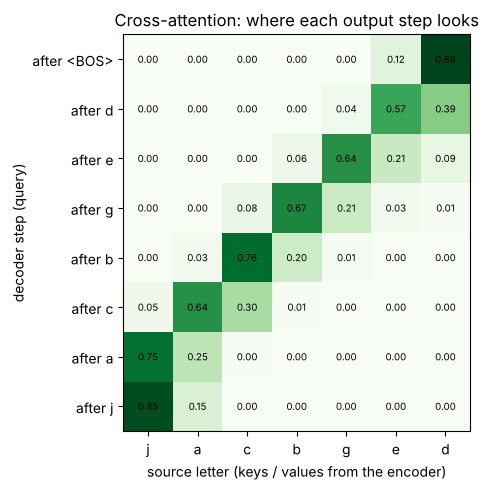

source position with the highest weight at each step: [6, 5, 4, 3, 2, 1, 0, 0]
a perfect reversal reads positions                     : [6, 5, 4, 3, 2, 1, 0] then EOS


In [8]:
src_ids = [stoi[c] for c in word]
out_ids = [BOS] + pred
with torch.no_grad():
    memory, src_pad = model.encode(torch.tensor([src_ids]))
    model.decode(torch.tensor([out_ids]), memory, src_pad)
W = model.dec[-1].last_cross[0].numpy()
plt.figure(figsize=(5.5, 5))
plt.imshow(W, cmap="Greens")
plt.xticks(range(len(word)), list(word)); plt.yticks(range(len(out_ids)), [f"after {itos[i]}" for i in out_ids])
plt.xlabel("source letter (keys / values from the encoder)"); plt.ylabel("decoder step (query)")
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        plt.text(j, i, f"{W[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Cross-attention: where each output step looks"); plt.tight_layout(); plt.show()
print("source position with the highest weight at each step:", W.argmax(1).tolist())
print("a perfect reversal reads positions                     :", list(range(len(word) - 1, -1, -1)), "then EOS")

![cross-attention](../images/ex12_cross_attention.png)

The weights form a clean **anti-diagonal**: when writing its 1st letter the decoder looks at the **last** source letter (0.88 on "d"), for the 2nd letter at the second-to-last, and so on: positions 6, 5, 4, 3, 2, 1, 0, exactly a reversal. When it's time for `<EOS>` it looks at the first letter again ("j", 0.85).

This is the notes' point that **cross-attention changes at every decoder step**: the decoder doesn't receive one fixed summary of the source; each query retrieves a different weighted mixture of the encoder memory. (Caveat from the notes: in real translation models, heads are rarely this clean or human-readable. This task was chosen to make the alignment visible.)

## 7 · Training vs inference: exposure bias
During training the decoder always sees the **correct** previous tokens (teacher forcing). At inference it sees **its own** outputs, so one mistake changes everything that follows. To see this we need a model that makes mistakes: the same network trained for only **60 steps**.

We score **each target position**:
- **teacher-forced:** the model is given the true prefix at every position (the training situation);
- **free-running:** the model's own greedy output is compared position by position with the truth (the inference situation).

In [9]:
def train_steps(n, seed=0):
    torch.manual_seed(seed); m = Seq2Seq(V); o = torch.optim.AdamW(m.parameters(), lr=1e-3)
    for _ in range(n):
        ix = torch.randint(0, len(S_all), (64,))
        l = F.cross_entropy(m(S_all[ix], Ti_all[ix]).reshape(-1, V), To_all[ix].reshape(-1), ignore_index=PAD)
        o.zero_grad(); l.backward(); o.step()
    return m

S_te, Ti_te, To_te = batchify(test_src, test_tgt)
weak = train_steps(60)
with torch.no_grad():
    pred_tf = weak(S_te, Ti_te).argmax(-1)
real = To_te != PAD
tf_tok = (pred_tf[real] == To_te[real]).float().mean().item()
tf_word = ((pred_tf == To_te) | ~real).all(1).float().mean().item()

hits, total, words, after_err = 0, 0, 0, []
for s_, t_ in zip(test_src, test_tgt):
    out = greedy(weak, s_)
    truth = t_ + [EOS]; mine = out + [EOS]
    first_err = next((i for i in range(len(truth)) if i >= len(mine) or mine[i] != truth[i]), None)
    hits += sum(1 for i in range(len(truth)) if i < len(mine) and mine[i] == truth[i]); total += len(truth)
    words += first_err is None
    if first_err is not None:
        rest = range(first_err + 1, len(truth))
        if len(rest): after_err.append(np.mean([i < len(mine) and mine[i] == truth[i] for i in rest]))
print(f"teacher-forced : token accuracy {tf_tok:.1%}   whole words {tf_word:.1%}")
print(f"free-running   : token accuracy {hits / total:.1%}   whole words {words / len(test_src):.1%}")
print(f"in free-running words with a mistake, positions AFTER the first mistake were right only {np.mean(after_err):.1%} of the time")

teacher-forced : token accuracy 90.5%   whole words 53.6%
free-running   : token accuracy 81.9%   whole words 53.6%
in free-running words with a mistake, positions AFTER the first mistake were right only 53.7% of the time


**What happened (60-step model):**
- **Teacher-forced token accuracy 90.5%**, but in **free-running** mode only **81.9%** of positions are right: the training-time number **overestimates** inference quality.
- **After its first mistake**, the model got only **53.7%** of the remaining positions right: one wrong token puts it in a situation it never saw in training (a wrong prefix), and errors snowball. That's **exposure bias**.
- Whole-word accuracy is the same 53.6% both ways. That's a property of greedy decoding: a word is fully right in free-running mode exactly when every teacher-forced step is right.

(The fully trained model makes no mistakes, so it shows no gap: exposure bias matters when a model is imperfect, i.e. always in real tasks.)

## 8 · The same task with a decoder-only model
A decoder-only (GPT-style) model has **no separate encoder and no cross-attention**: source and target become **one causal stream**, `source <SEP> target <EOS>`, and the loss is computed only on the target part. Same width, 4 causal layers (≈ the same parameter count), same training budget.

In [10]:
SEP = V          # one extra token
class DecoderOnly(nn.Module):
    def __init__(self, V, d=64, h=4, n_layers=4, max_len=24):
        super().__init__()
        self.emb, self.pos = nn.Embedding(V, d), nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, h, 4 * d, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V)
    def forward(self, x):
        T = x.shape[1]
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
        h = self.blocks(self.emb(x) + self.pos(torch.arange(T)), mask=causal, is_causal=True)
        return self.head(self.ln(h))

def stream(src, tgt):
    seq = src + [SEP] + tgt + [EOS]
    labels = [PAD] * (len(src) + 1) + tgt + [EOS]           # loss only on target tokens
    return seq, labels
L_MAX = 2 * MAXLEN + 2
pairs = [stream(s, t) for s, t in zip(train_src, train_tgt)]
X_do = pad([p_[0][:-1] for p_ in pairs], L_MAX); Y_do = pad([p_[1][1:] for p_ in pairs], L_MAX)

torch.manual_seed(0)
gpt = DecoderOnly(V + 1)
print(f"decoder-only parameters: {sum(p.numel() for p in gpt.parameters()):,}   (encoder-decoder: {sum(p.numel() for p in model.parameters()):,})")
opt = torch.optim.AdamW(gpt.parameters(), lr=1e-3); t0 = time.time()
for step in range(1501):
    ix = torch.randint(0, len(X_do), (64,))
    l = F.cross_entropy(gpt(X_do[ix]).reshape(-1, V + 1), Y_do[ix].reshape(-1), ignore_index=PAD)
    opt.zero_grad(); l.backward(); opt.step()
    if step % 500 == 0: print(f"step {step:>4}: loss {l.item():.4f}")
print(f"trained in {time.time() - t0:.0f} s")

@torch.no_grad()
def gpt_greedy(src):
    seq = src + [SEP]; out = []
    for _ in range(MAXLEN + 1):
        nxt = int(gpt(torch.tensor([seq]))[0, -1, :V].argmax())
        if nxt == EOS: break
        out.append(nxt); seq.append(nxt)
    return out
acc = np.mean([gpt_greedy(s) == t for s, t in zip(test_src, test_tgt)])
print(f"decoder-only exact-match accuracy on the same 1,000 words: {acc:.1%}")
print("example:", word, "->", "".join(itos[i] for i in gpt_greedy([stoi[c] for c in word])))

decoder-only parameters: 203,406   (encoder-decoder: 238,285)
step    0: loss 2.8613


step  500: loss 0.0015


step 1000: loss 0.0005


step 1500: loss 0.0003
trained in 37 s


decoder-only exact-match accuracy on the same 1,000 words: 100.0%
example: jacbged -> degbcaj


**Result:** the decoder-only model (203,406 parameters, no encoder, no cross-attention) also reached **100%** in the same 1,500 steps and the same time.

So for this task **both architectures work**, which is the notes' message: "**there is no universal winner**". The difference is the **information flow**: the encoder-decoder builds a bidirectional source representation and **queries** it through cross-attention; the decoder-only model keeps the source inside **one causal stream** and reaches it through ordinary (masked) self-attention. Decoder-only models dominate general-purpose LLMs because *any* task can be written as "prompt → continuation"; encoder-decoder models remain natural for clean source → target transformations (translation, speech-to-text, captioning).

## 9 · What a KV cache saves
At inference, the prefix doesn't change, so its keys and values can be **stored** instead of recomputed. Counting the token positions the decoder has to process to generate T tokens:

In [11]:
for T in [7, 100, 1000]:
    print(f"T = {T:>5}: without cache {T * (T + 1) // 2:>9,} positions processed   with cache {T:>5,}   ({(T + 1) / 2:.0f}× less)")

# memory cost: layers × sequence length × heads × head dim × 2 (K and V) × bytes, per sequence
layers, seq, heads, hd, bytes_ = 32, 4096, 32, 128, 2
print(f"\nKV cache for a 32-layer, 32-head (head dim 128) model at 4,096 tokens in fp16: "
      f"{layers * seq * heads * hd * 2 * bytes_ / 1e9:.2f} GB per sequence")

T =     7: without cache        28 positions processed   with cache     7   (4× less)
T =   100: without cache     5,050 positions processed   with cache   100   (50× less)
T =  1000: without cache   500,500 positions processed   with cache 1,000   (500× less)

KV cache for a 32-layer, 32-head (head dim 128) model at 4,096 tokens in fp16: 2.15 GB per sequence


A KV cache trades **memory for speed**: generation work grows linearly instead of quadratically, but the cache itself takes gigabytes for long contexts. Grouped-query / multi-query attention (fewer K/V heads) exist to shrink it. In an encoder-decoder, the **encoder memory** (and its cross-attention K/V) is computed once and reused at every step too: our `greedy` function calls `model.encode` exactly once.

## 10 · Choosing an architecture (the notes' decision process)

| Task | Choice | Why (what must be visible at prediction time) |
|---|---|---|
| sentiment classification | **encoder-only** | one label; the whole input, both directions |
| code autocomplete / chat | **decoder-only** | output continues a prefix; one causal stream |
| translation (English → Hindi) | **encoder-decoder** | separate source and target; the decoder queries the source at every step |
| summarization | either | both work; the encoder gives a natural source representation |
| image captioning, speech-to-text | **encoder-decoder pattern** | an image/audio encoder provides the memory; a text decoder cross-attends |

**The fastest diagnostic question (from the notes):** *at this exact prediction position, what is the model allowed to see, and through which attention path can it reach it?*

## ✅ Check yourself
1. Correct-token probabilities 0.8, 0.5, 0.25: sequence probability? NLL? *(0.1; −ln 0.1 = 2.303)*
2. Is the encoder of a translation model autoregressive? *(no, it's bidirectional; the decoder is autoregressive)*
3. In cross-attention, where do Q, K and V come from? *(Q from the decoder; K and V from the encoder memory)*
4. S = 12, T = 7, d = 256, 8 heads: shapes of memory, decoder hidden states, cross-attention scores per head? *([B, 12, 256]; [B, 7, 256]; [B, 8, 7, 12])*
5. What is teacher forcing, and what problem does it create? *(feeding the true previous tokens in training; exposure bias at inference)*
6. Which parts can be cached during generation? *(encoder memory and its cross-attention K/V; the decoder's self-attention K/V for earlier tokens)*